# Symptom2Disease NLP Classification: BERT vs TF-IDF

Disease classification from symptom text using **two NLP algorithms**, compared on the same train/validation/test split:

1. **Frozen BERT feature extractor + classifier head** (pretrained BERT embeddings; only the small dense head is trained)
2. **TF-IDF + Logistic Regression** (traditional baseline)

Includes:
- Dataset loading and inspection
- Data cleaning and preprocessing
- WordCloud and class distribution
- BERT tokenization and classification model
- TF-IDF + Logistic Regression model
- Accuracy, Macro-F1 and Weighted-F1, classification reports, confusion matrices
- BERT vs TF-IDF comparison
- Custom symptom prediction with both models
- Model saving

**Run all cells from top to bottom** (Runtime > Run all) so every model is trained before the comparison cell.

In [1]:
# ============================================================
# STEP 1: INSTALL REQUIRED LIBRARIES
# ============================================================

!pip install -q transformers wget wordcloud

In [2]:
# ============================================================
# STEP 2: IMPORT LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import wget
import gc
import os

warnings.filterwarnings("ignore")

import tensorflow as tf
print("TensorFlow version:", tf.__version__)

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Input, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, LearningRateScheduler, ModelCheckpoint
from tensorflow.keras.optimizers import Adam

# Import PyTorch and the standard AutoModel wrapper to bypass the TF integration issues
import torch
from transformers import AutoTokenizer, AutoModel

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

from wordcloud import WordCloud

TensorFlow version: 2.21.0


## Step 3: Download and import text-cleaning helper functions

In [3]:
helper_url = (
    "https://raw.githubusercontent.com/"
    "yogawicaksana/helper_prabowo/main/helper_prabowo_ml.py"
)

wget.download(helper_url, "helper_prabowo_ml.py")
print("\nHelper file downloaded.")


Helper file downloaded.


In [4]:
from helper_prabowo_ml import (
    clean_html,
    remove_,
    remove_digits,
    remove_special_characters,
    removeStopWords,
    remove_links,
    punct,
    email_address,
    lower,
    non_ascii
)

print("Helper functions imported successfully.")

Helper functions imported successfully.


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


## Step 4: Upload and load Symptom2Disease.csv

Run the next cell and upload your `Symptom2Disease.csv` file.

In [5]:
from google.colab import files

uploaded = files.upload()

Saving Symptom2Disease (1).csv to Symptom2Disease (1) (2).csv


In [6]:
import os

# Check for alternative uploaded filenames if the standard name is missing
if os.path.exists("Symptom2Disease.csv"):
    file_path = "Symptom2Disease.csv"
elif os.path.exists("Symptom2Disease (1).csv"):
    file_path = "Symptom2Disease (1).csv"
elif os.path.exists("Symptom2Disease (1) (1).csv"):
    file_path = "Symptom2Disease (1) (1).csv"
else:
    raise FileNotFoundError("Could not find any Symptom2Disease CSV file. Please upload it again.")

df = pd.read_csv(file_path)

print(f"Dataset loaded successfully from: {file_path}")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully from: Symptom2Disease (1).csv
Shape: (1200, 3)


,Unnamed: 0,label,text
0,0,Psoriasis,I have been experiencing a skin rash on my arm...
1,1,Psoriasis,"My skin has been peeling, especially on my kne..."
2,2,Psoriasis,I have been experiencing joint pain in my fing...
3,3,Psoriasis,"There is a silver like dusting on my skin, esp..."
4,4,Psoriasis,"My nails have small dents or pits in them, and..."


## Step 5: Initial dataset inspection

In [7]:
print("Dataset shape:")
print(df.shape)

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all"))

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset shape:
(1200, 3)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  1200 non-null   int64 
 1   label       1200 non-null   object
 2   text        1200 non-null   object
dtypes: int64(1), object(2)
memory usage: 28.3+ KB

Descriptive statistics:


,Unnamed: 0,label,text
count,1200.000000,1200,1200
unique,NaN,24,1153
top,NaN,Psoriasis,"I've been feeling extremely scratchy, sick, an..."
freq,NaN,50,4
mean,149.500000,NaN,NaN
std,86.638166,NaN,NaN
min,0.000000,NaN,NaN
25%,74.750000,NaN,NaN
50%,149.500000,NaN,NaN
75%,224.250000,NaN,NaN



Missing values:
Unnamed: 0    0
label         0
text          0
dtype: int64

Duplicate rows:
0


## Step 6: Remove unnecessary column and duplicate rows

In [8]:
if "Unnamed: 0" in df.columns:
    df.drop("Unnamed: 0", axis=1, inplace=True)

print("Columns:")
print(df.columns.tolist())

before = df.shape[0]
df = df.drop_duplicates()
after = df.shape[0]

print("\nRows before removing duplicates:", before)
print("Rows after removing duplicates:", after)
print("Duplicates removed:", before - after)

Columns:
['label', 'text']

Rows before removing duplicates: 1200
Rows after removing duplicates: 1153
Duplicates removed: 47


## Step 7: Check the text and label columns

In [9]:
print("Text examples:")
display(df["text"].head())

print("\nLabel examples:")
display(df["label"].head())

Text examples:


,text
0,I have been experiencing a skin rash on my arm...
1,"My skin has been peeling, especially on my kne..."
2,I have been experiencing joint pain in my fing...
3,"There is a silver like dusting on my skin, esp..."
4,"My nails have small dents or pits in them, and..."



Label examples:


,label
0,Psoriasis
1,Psoriasis
2,Psoriasis
3,Psoriasis
4,Psoriasis


## Step 8: Word Cloud

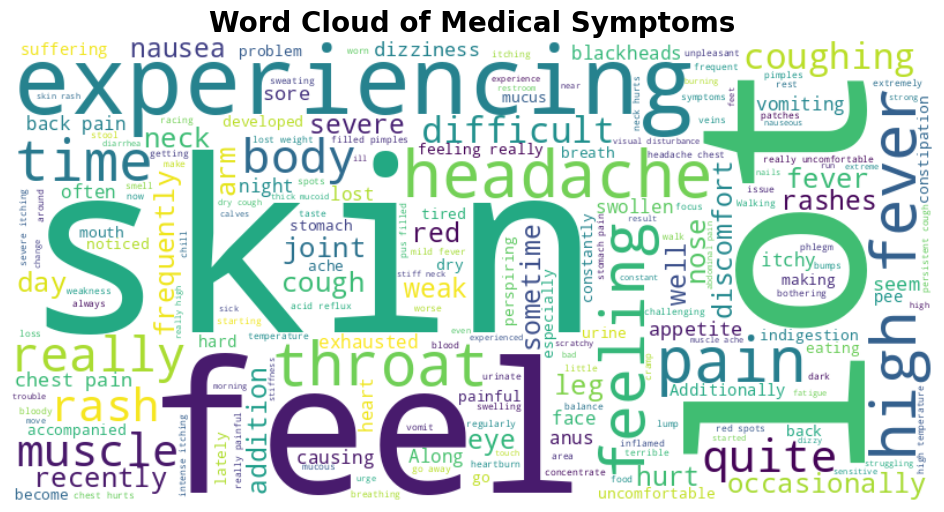

In [10]:
text_data = " ".join(df["text"].astype(str))

wc = WordCloud(
    width=800,
    height=400,
    random_state=101,
    background_color="white"
).generate(text_data)

plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title(
    "Word Cloud of Medical Symptoms",
    fontsize=20,
    fontweight="bold"
)
plt.show()

## Step 9: Number of words in each symptom description

In [11]:
df["num_words"] = df["text"].apply(
    lambda x: len(str(x).split())
)

display(df["num_words"].describe())

,num_words
count,1153.000000
mean,30.625325
std,6.717653
min,12.000000
25%,26.000000
50%,30.000000
75%,35.000000
max,55.000000


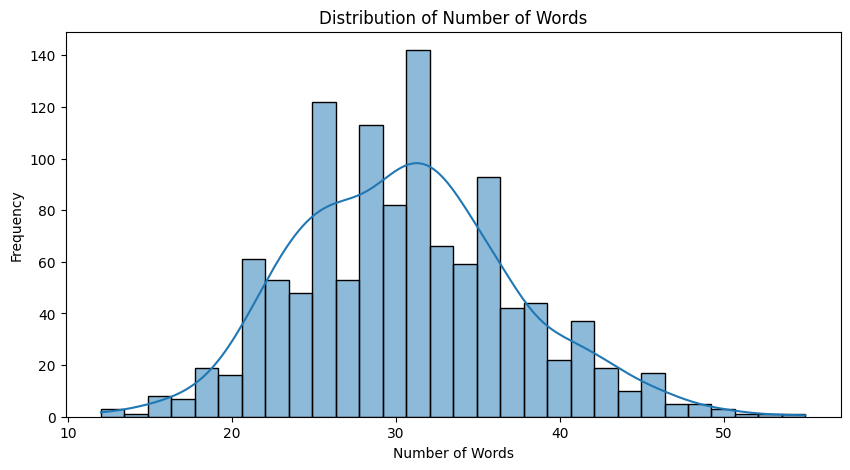

In [12]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["num_words"],
    bins=30,
    kde=True
)

plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Distribution of Number of Words")
plt.show()

## Step 10: Disease class distribution

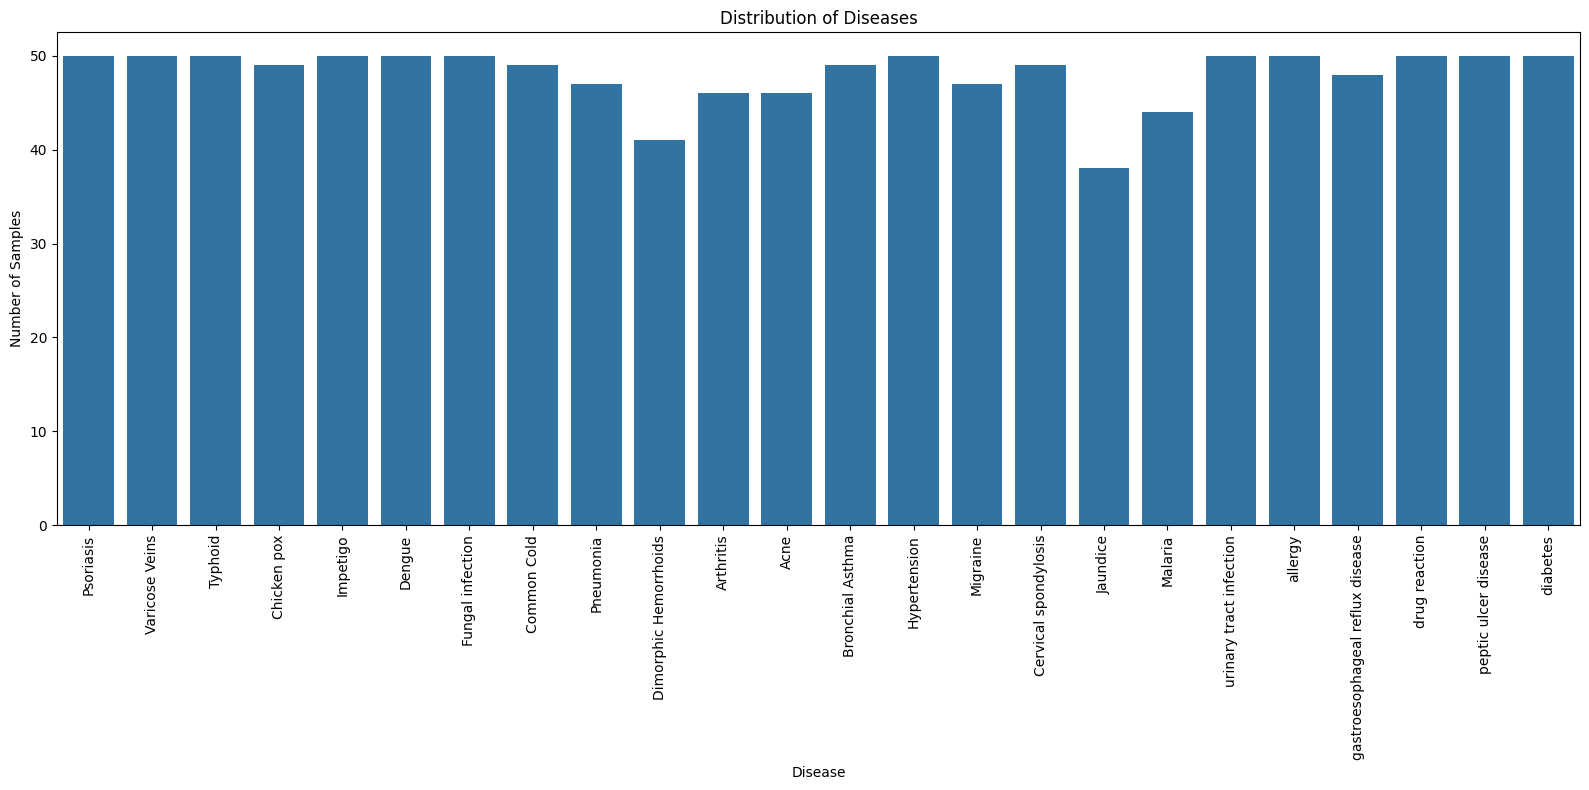

In [13]:
plt.figure(figsize=(16, 8))

sns.countplot(
    x="label",
    data=df
)

plt.xticks(rotation=90)
plt.xlabel("Disease")
plt.ylabel("Number of Samples")
plt.title("Distribution of Diseases")
plt.tight_layout()
plt.show()

## Step 11: Text preprocessing

In [14]:
def clean_text(data, col):
    data = data.copy()

    data[col] = data[col].apply(clean_html)
    data[col] = data[col].apply(email_address)
    data[col] = data[col].apply(remove_)
    data[col] = data[col].apply(remove_digits)
    data[col] = data[col].apply(remove_links)
    data[col] = data[col].apply(remove_special_characters)
    data[col] = data[col].apply(removeStopWords)
    data[col] = data[col].apply(non_ascii)
    data[col] = data[col].apply(punct)
    data[col] = data[col].apply(lower)

    return data

preprocessed_df = clean_text(df, "text")

display(preprocessed_df.head())

,label,text,num_words
0,Psoriasis,experiencing skin rash arms legs torso past we...,28
1,Psoriasis,my skin peeling especially knees elbows scalp ...,23
2,Psoriasis,experiencing joint pain fingers wrists knees t...,28
3,Psoriasis,there silver dusting skin especially lower bac...,32
4,Psoriasis,my nails small dents pits them often feel infl...,27


## Step 12: Compare original and cleaned text

In [15]:
for i in range(min(5, len(df))):
    print("Original:")
    print(df["text"].iloc[i])

    print("\nCleaned:")
    print(preprocessed_df["text"].iloc[i])

    print("-" * 80)

Original:
I have been experiencing a skin rash on my arms, legs, and torso for the past few weeks. It is red, itchy, and covered in dry, scaly patches.

Cleaned:
experiencing skin rash arms legs torso past weeks red itchy covered dry scaly patches
--------------------------------------------------------------------------------
Original:
My skin has been peeling, especially on my knees, elbows, and scalp. This peeling is often accompanied by a burning or stinging sensation.

Cleaned:
my skin peeling especially knees elbows scalp peeling often accompanied burning stinging sensation
--------------------------------------------------------------------------------
Original:
I have been experiencing joint pain in my fingers, wrists, and knees. The pain is often achy and throbbing, and it gets worse when I move my joints.

Cleaned:
experiencing joint pain fingers wrists knees the pain often achy throbbing gets worse move joints
-----------------------------------------------------------------

## Step 13: Encode disease labels

In [16]:
encoder = LabelEncoder()

preprocessed_df["label_encoded"] = encoder.fit_transform(
    preprocessed_df["label"]
)

num_classes = len(encoder.classes_)

print("Number of disease classes:", num_classes)

labels_dict = {
    idx: label
    for idx, label in enumerate(encoder.classes_)
}

print("\nLabel mapping:")
for idx, label in labels_dict.items():
    print(idx, "->", label)

Number of disease classes: 24

Label mapping:
0 -> Acne
1 -> Arthritis
2 -> Bronchial Asthma
3 -> Cervical spondylosis
4 -> Chicken pox
5 -> Common Cold
6 -> Dengue
7 -> Dimorphic Hemorrhoids
8 -> Fungal infection
9 -> Hypertension
10 -> Impetigo
11 -> Jaundice
12 -> Malaria
13 -> Migraine
14 -> Pneumonia
15 -> Psoriasis
16 -> Typhoid
17 -> Varicose Veins
18 -> allergy
19 -> diabetes
20 -> drug reaction
21 -> gastroesophageal reflux disease
22 -> peptic ulcer disease
23 -> urinary tract infection


## Step 14: Train / validation / test split

In [17]:
train_df, temp_df = train_test_split(
    preprocessed_df,
    test_size=0.30,
    stratify=preprocessed_df["label_encoded"],
    random_state=101
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label_encoded"],
    random_state=101
)

print("Training samples:", len(train_df))
print("Validation samples:", len(val_df))
print("Testing samples:", len(test_df))

Training samples: 807
Validation samples: 173
Testing samples: 173


## Additional NLP Algorithm: TF-IDF + Logistic Regression

This section adds a traditional machine-learning NLP baseline alongside the existing BERT model. TF-IDF converts symptom descriptions into weighted word and phrase features; Logistic Regression uses those features to classify the disease label. The same train/validation/test split is reused so the results can be compared fairly with BERT. The TF-IDF vectorizer is fitted only on training text to avoid data leakage.

In [18]:
# TF-IDF and Logistic Regression imports
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

print('TF-IDF + Logistic Regression libraries imported.')

TF-IDF + Logistic Regression libraries imported.


In [19]:
# Fit TF-IDF on training text only; transform validation and test text
tfidf_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),       # unigrams and bigrams
    max_features=50000,
    sublinear_tf=True,
    min_df=2
)

X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['text'].astype(str))
X_val_tfidf = tfidf_vectorizer.transform(val_df['text'].astype(str))
X_test_tfidf = tfidf_vectorizer.transform(test_df['text'].astype(str))

y_train_tfidf = train_df['label_encoded'].to_numpy()
y_val_tfidf = val_df['label_encoded'].to_numpy()
y_test_tfidf = test_df['label_encoded'].to_numpy()

print('TF-IDF feature matrix shapes:')
print('Train:', X_train_tfidf.shape)
print('Validation:', X_val_tfidf.shape)
print('Test:', X_test_tfidf.shape)

TF-IDF feature matrix shapes:
Train: (807, 3063)
Validation: (173, 3063)
Test: (173, 3063)


In [20]:
# Train the TF-IDF + Logistic Regression classifier
tfidf_model = LogisticRegression(
    max_iter=2000,
    class_weight='balanced',
    random_state=101
)
tfidf_model.fit(X_train_tfidf, y_train_tfidf)

tfidf_val_pred = tfidf_model.predict(X_val_tfidf)
print('Validation Accuracy:', round(accuracy_score(y_val_tfidf, tfidf_val_pred) * 100, 2), '%')
print('Validation Macro-F1:', round(f1_score(y_val_tfidf, tfidf_val_pred, average='macro'), 4))

Validation Accuracy: 95.38 %
Validation Macro-F1: 0.9544


In [21]:
# Evaluate on the held-out test set
tfidf_test_pred = tfidf_model.predict(X_test_tfidf)
tfidf_accuracy = accuracy_score(y_test_tfidf, tfidf_test_pred)
tfidf_macro_f1 = f1_score(y_test_tfidf, tfidf_test_pred, average='macro')
tfidf_weighted_f1 = f1_score(y_test_tfidf, tfidf_test_pred, average='weighted')

print('TF-IDF + Logistic Regression — Test Results')
print('=' * 55)
print(f'Accuracy:    {tfidf_accuracy * 100:.2f}%')
print(f'Macro-F1:    {tfidf_macro_f1:.4f}')
print(f'Weighted-F1: {tfidf_weighted_f1:.4f}')
print('\nClassification Report:')
print(classification_report(
    y_test_tfidf,
    tfidf_test_pred,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

TF-IDF + Logistic Regression — Test Results
Accuracy:    94.80%
Macro-F1:    0.9486
Weighted-F1: 0.9483

Classification Report:
                                 precision    recall  f1-score   support

                           Acne       1.00      1.00      1.00         7
                      Arthritis       1.00      1.00      1.00         7
               Bronchial Asthma       1.00      1.00      1.00         7
           Cervical spondylosis       1.00      1.00      1.00         7
                    Chicken pox       1.00      1.00      1.00         7
                    Common Cold       1.00      1.00      1.00         7
                         Dengue       0.80      1.00      0.89         8
          Dimorphic Hemorrhoids       1.00      1.00      1.00         6
               Fungal infection       1.00      1.00      1.00         7
                   Hypertension       1.00      1.00      1.00         8
                       Impetigo       0.89      1.00      0.94      

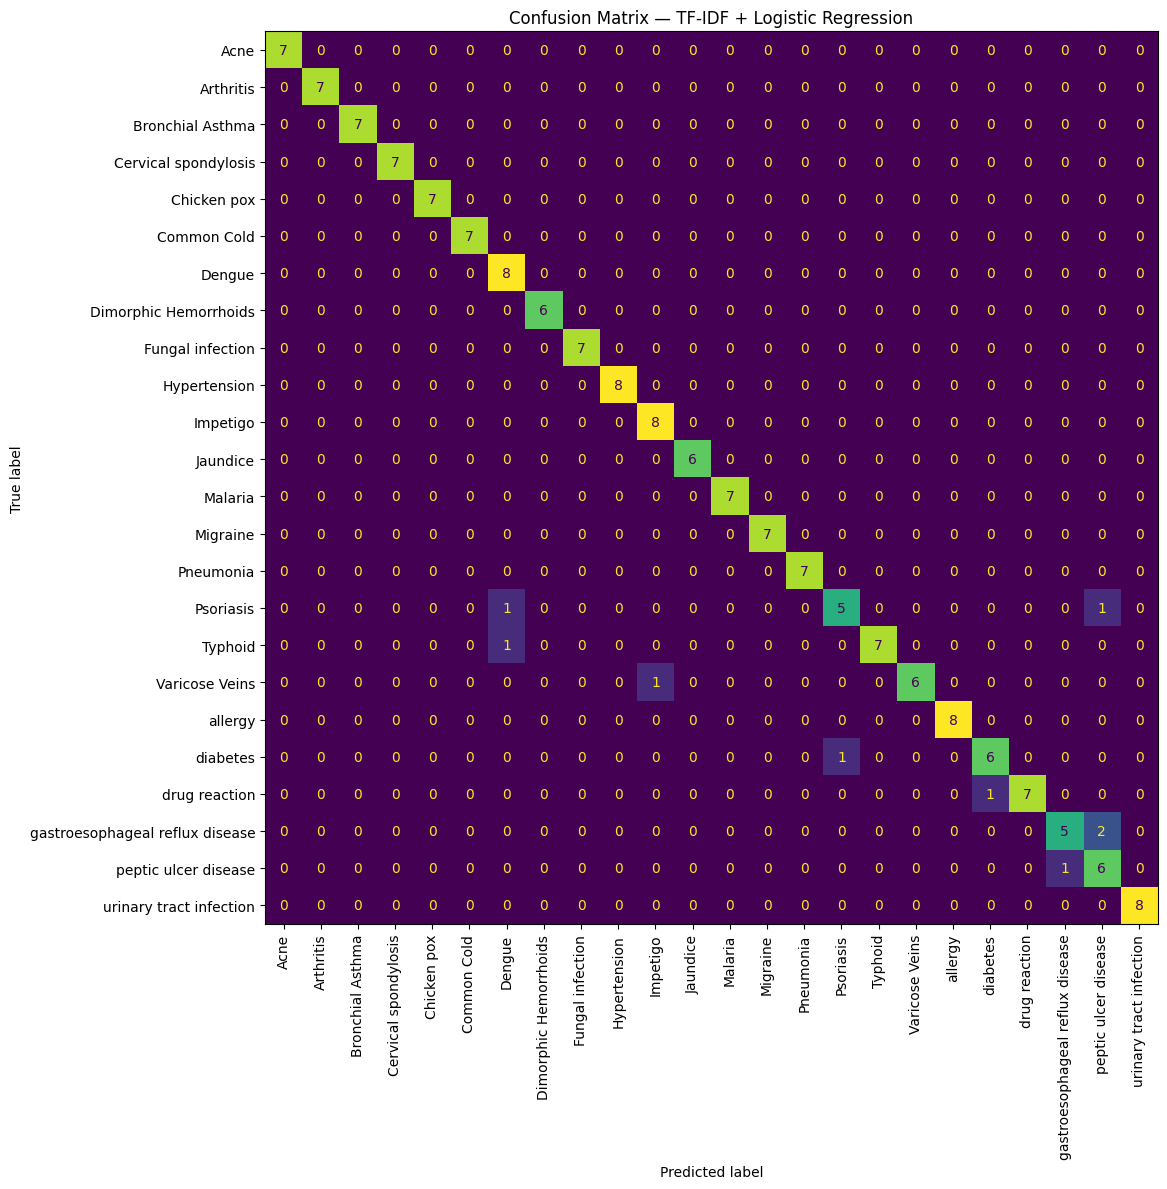

In [22]:
# Confusion matrix for the TF-IDF model
tfidf_cm = confusion_matrix(
    y_test_tfidf,
    tfidf_test_pred,
    labels=np.arange(len(encoder.classes_))
)
fig, ax = plt.subplots(figsize=(12, 12))
ConfusionMatrixDisplay(
    confusion_matrix=tfidf_cm,
    display_labels=encoder.classes_
).plot(ax=ax, xticks_rotation=90, colorbar=False, values_format='d')
plt.title('Confusion Matrix — TF-IDF + Logistic Regression')
plt.tight_layout()
plt.show()

In [23]:
# Predict a disease for a new symptom description using the TF-IDF model
# Apply the same text-cleaning steps used to create preprocessed_df.
def clean_single_text(text):
    text = clean_html(text)
    text = email_address(text)
    text = remove_(text)
    text = remove_digits(text)
    text = remove_links(text)
    text = remove_special_characters(text)
    text = removeStopWords(text)
    text = non_ascii(text)
    text = punct(text)
    text = lower(text)
    return text

new_symptoms = "I have stiffness in my neck, swollen joints, and pain when walking."
new_symptoms_clean = clean_single_text(new_symptoms)
new_symptoms_vector = tfidf_vectorizer.transform([new_symptoms_clean])
new_probs = tfidf_model.predict_proba(new_symptoms_vector)[0]
best_idx = int(np.argmax(new_probs))
print('Input symptoms:', new_symptoms)
print('TF-IDF predicted disease:', encoder.classes_[best_idx])
print('Model probability:', round(float(new_probs[best_idx]) * 100, 2), '%')

Input symptoms: I have stiffness in my neck, swollen joints, and pain when walking.
TF-IDF predicted disease: Arthritis
Model probability: 20.66 %


## Step 15: Load pretrained BERT tokenizer

In [24]:
MODEL_NAME = "ajtamayoh/Symptoms_to_Diagnosis_SonatafyAI_BERT_v1"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully.")

Tokenizer loaded successfully.


## Step 16: Load BERT base model

The pretrained BERT is loaded with PyTorch `AutoModel` and used as a **frozen feature extractor** (its weights are not updated). It is wrapped in a custom Keras layer, and our own classification layers are added on top and trained.

In [25]:
try:
    bert_model = AutoModel.from_pretrained(MODEL_NAME)
except Exception as e:
    print("Error loading model:", e)

print("BERT model loaded successfully via PyTorch.")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: ajtamayoh/Symptoms_to_Diagnosis_SonatafyAI_BERT_v1
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT model loaded successfully via PyTorch.


## Step 17: Tokenize the dataset

In [26]:
max_len = 170

X_train = tokenizer(
    train_df["text"].tolist(),
    max_length=max_len,
    padding="max_length",
    truncation=True,
    add_special_tokens=True,
    return_attention_mask=True,
    return_tensors="np",
    return_token_type_ids=False
)

X_val = tokenizer(
    val_df["text"].tolist(),
    max_length=max_len,
    padding="max_length",
    truncation=True,
    add_special_tokens=True,
    return_attention_mask=True,
    return_tensors="np",
    return_token_type_ids=False
)

X_test = tokenizer(
    test_df["text"].tolist(),
    max_length=max_len,
    padding="max_length",
    truncation=True,
    add_special_tokens=True,
    return_attention_mask=True,
    return_tensors="np",
    return_token_type_ids=False
)

print("Tokenization completed.")
print("Maximum sequence length:", max_len)

Tokenization completed.
Maximum sequence length: 170


## Step 18: Prepare integer labels

In [27]:
y_train = train_df["label_encoded"].values
y_val = val_df["label_encoded"].values
y_test = test_df["label_encoded"].values

print("Training labels shape:", y_train.shape)
print("Validation labels shape:", y_val.shape)
print("Testing labels shape:", y_test.shape)

Training labels shape: (807,)
Validation labels shape: (173,)
Testing labels shape: (173,)


## Step 19: Build BERT classification model

In [28]:
import tensorflow as tf
import torch
from tensorflow.keras.layers import Layer, Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model

# Define a custom Keras Layer that wraps our PyTorch BERT model
class TFBertBridge(Layer):
    def __init__(self, pt_model, **kwargs):
        super(TFBertBridge, self).__init__(**kwargs)
        self.pt_model = pt_model
        # Freeze the BERT weights
        for param in self.pt_model.parameters():
            param.requires_grad = False

    @tf.custom_gradient
    def call(self, inputs):
        input_ids, attention_mask = inputs

        def custom_grad(dy):
            # Return None gradients since the BERT weights are frozen
            return [None, None]

        # PyTorch forward pass wrapped in tf.numpy_function
        def torch_forward(ids_np, mask_np):
            ids_pt = torch.from_numpy(ids_np).long()
            mask_pt = torch.from_numpy(mask_np).long()

            with torch.no_grad():
                outputs = self.pt_model(input_ids=ids_pt, attention_mask=mask_pt)
                # Return the last_hidden_state
                return outputs.last_hidden_state.numpy()

        # Use tf.numpy_function to bridge the PyTorch computation graph
        last_hidden_state = tf.numpy_function(
            torch_forward,
            [input_ids, attention_mask],
            tf.float32
        )

        # Restore static shape for downstream Keras layers
        last_hidden_state.set_shape((None, max_len, 768))
        return last_hidden_state, custom_grad

# Instantiate our bridge layer
bert_bridge = TFBertBridge(bert_model)

# Rebuild the model structure
input_ids = Input(
    shape=(max_len,),
    dtype=tf.int32,
    name="input_ids"
)

attention_mask = Input(
    shape=(max_len,),
    dtype=tf.int32,
    name="attention_mask"
)

# Pass inputs through our custom bridge
bert_output = bert_bridge([input_ids, attention_mask])

# Use the [CLS] token representation
cls_embedding = bert_output[:, 0, :]

output = Dense(
    128,
    activation="relu"
)(cls_embedding)

output = BatchNormalization()(output)
output = Dropout(0.2)(output)

output = Dense(
    64,
    activation="relu"
)(output)

output = BatchNormalization()(output)
output = Dropout(0.1)(output)

output = Dense(
    32,
    activation="relu"
)(output)

output = Dense(
    num_classes,
    activation="softmax"
)(output)

model = Model(
    inputs=[input_ids, attention_mask],
    outputs=output
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_ids           │ (None, 170)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ attention_mask      │ (None, 170)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tf_bert_bridge      │ (None, 170, 768)  │          0 │ input_ids[0][0],  │
│ (TFBertBridge)      │                   │            │ attention_mask[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 768)       │          0 │ tf_bert_bridge[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 128)       │     98,432 │ get_item[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 128)       │        512 │ dense[0][0]       │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 64)        │      8,256 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_1[0][0]     │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      2,080 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 24)        │        792 │ dense_2[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 110,328 (430.97 KB)

 Trainable params: 109,944 (429.47 KB)

 Non-trainable params: 384 (1.50 KB)

## Step 20: Compile the model

In [29]:
model.compile(
    optimizer=Adam(
        learning_rate=5e-5,
        epsilon=2e-7,
        clipnorm=1.0
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


## Step 21: Define learning-rate scheduler and callbacks

In [30]:
def time_based_decay(epoch, lr):
    decay_rate = 1e-5
    decay_epoch = 10

    return lr * (
        1 /
        (
            1 + decay_rate * epoch / decay_epoch
        )
    )

early_stopping = EarlyStopping(
    monitor="val_accuracy",
    patience=10,
    verbose=1,
    mode="max",
    restore_best_weights=True
)

model_checkpoint = ModelCheckpoint(
    filepath="symptoms_disease_classifier.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1
)

lr_scheduler = LearningRateScheduler(
    schedule=time_based_decay,
    verbose=1
)

print("Callbacks created successfully.")

Callbacks created successfully.


## Step 22: Train the classifier head on top of frozen BERT

Training runs up to 40 epochs with early stopping (validation accuracy was still improving at 20 epochs).

In [31]:
import torch
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint

# ---- 1. Compute BERT [CLS] embeddings ONCE (frozen BERT never changes) ----
device = "cuda" if torch.cuda.is_available() else "cpu"
bert_model.to(device).eval()
print("Computing BERT embeddings on:", device)

def embed_texts(texts, batch_size=32):
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tokenizer(
            texts[i:i + batch_size],
            max_length=max_len,
            padding=True,              # pad only to the longest text in the batch (faster)
            truncation=True,
            return_tensors="pt"
        )
        enc = {k: v.to(device) for k, v in enc.items() if k in ("input_ids", "attention_mask")}
        with torch.no_grad():
            out.append(bert_model(**enc).last_hidden_state[:, 0, :].cpu().numpy())
    return np.vstack(out)

E_train = embed_texts(train_df["text"].tolist())
E_val   = embed_texts(val_df["text"].tolist())
bert_model.to("cpu")   # the Keras bridge layer expects BERT on CPU
print("Embeddings:", E_train.shape, E_val.shape)

# ---- 2. Small classifier head on top of the embeddings ----
emb_in = Input(shape=(768,), name="cls_embedding")
x = Dense(128, activation="relu")(emb_in)
x = BatchNormalization()(x)
x = Dropout(0.2)(x)
x = Dense(64, activation="relu")(x)
x = BatchNormalization()(x)
x = Dropout(0.1)(x)
x = Dense(32, activation="relu")(x)
x = Dense(num_classes, activation="softmax")(x)
head_model = Model(emb_in, x)

head_model.compile(
    optimizer=Adam(learning_rate=1e-3, clipnorm=1.0),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

head_checkpoint = ModelCheckpoint(
    filepath="symptoms_disease_classifier_weights.weights.h5",
    monitor="val_accuracy", mode="max",
    save_best_only=True, save_weights_only=True, verbose=0
)

history = head_model.fit(
    E_train, y_train,
    epochs=40,
    batch_size=16,
    validation_data=(E_val, y_val),
    callbacks=[early_stopping, head_checkpoint]
)

# ---- 3. Copy the trained head weights into the full BERT model ----
full_layers = [l for l in model.layers if l.weights]
head_layers = [l for l in head_model.layers if l.weights]
assert len(full_layers) == len(head_layers)
for a, b in zip(full_layers, head_layers):
    a.set_weights(b.get_weights())

model.compile(
    optimizer=Adam(learning_rate=5e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
    jit_compile=False
)
print("Head trained and copied into the full model.")

Computing BERT embeddings on: cuda
Embeddings: (807, 768) (173, 768)
Epoch 1/40
51/51 ━━━━━━━━━━━━━━━━━━━━ 31s 333ms/step - accuracy: 0.4089 - loss: 2.2752 - val_accuracy: 0.7225 - val_loss: 1.7296
Epoch 2/40
51/51 ━━━━━━━━━━━━━━━━━━━━ 16s 6ms/step - accuracy: 0.7546 - loss: 1.1577 - val_accuracy: 0.8497 - val_loss: 0.7806
Epoch 3/40
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8488 - loss: 0.7232 - val_accuracy: 0.9017 - val_loss: 0.4502
Epoch 4/40
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9170 - loss: 0.4376 - val_accuracy: 0.9249 - val_loss: 0.2974
Epoch 5/40
51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9356 - loss: 0.3109 - val_accuracy: 0.9422 - val_loss: 0.2325
Epoch 6/40
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9566 - loss: 0.2303 - val_accuracy: 0.9711 - val_loss: 0.1545
Epoch 7/40
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9653 - loss: 0.1864 - val_accuracy: 0.9595 - val_loss: 0.1590
Epoch 8/40
51/51 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/

## Step 23: Plot training and validation loss

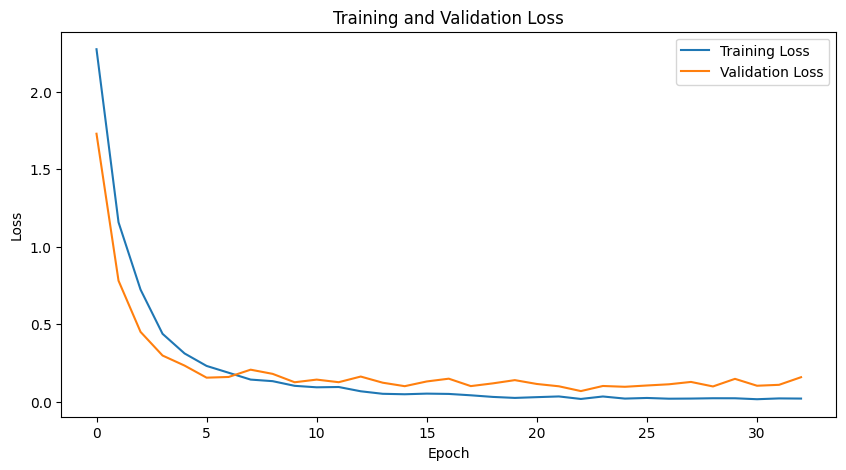

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

## Step 24: Plot training and validation accuracy

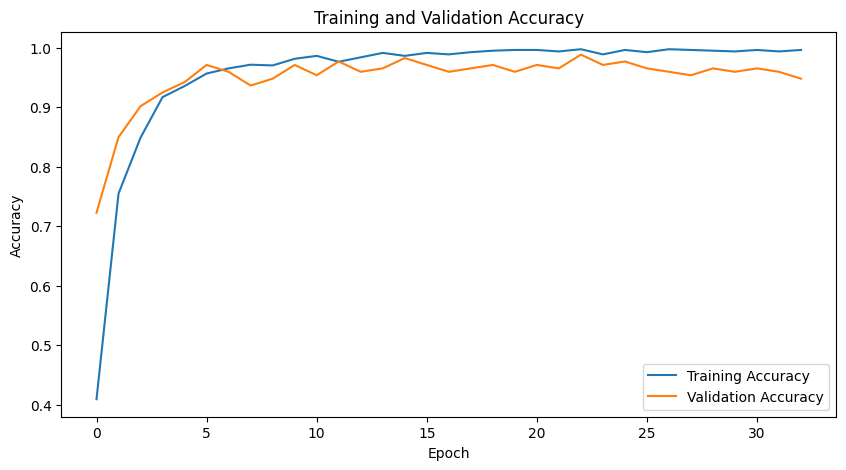

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.show()

## Step 25: Evaluate the model on the test set

In [34]:
test_loss, test_accuracy = model.evaluate(
    {
        "input_ids": X_test["input_ids"],
        "attention_mask": X_test["attention_mask"]
    },
    y_test,
    verbose=1
)

print("======================================")
print("MODEL EVALUATION")
print("======================================")
print("Categorical Crossentropy Loss:", round(test_loss, 4))
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

6/6 ━━━━━━━━━━━━━━━━━━━━ 55s 9s/step - accuracy: 0.9538 - loss: 0.2895
MODEL EVALUATION
Categorical Crossentropy Loss: 0.2895
Test Accuracy: 95.38 %


## Step 26: Generate predictions

In [35]:
predictions = model.predict(
    {
        "input_ids": X_test["input_ids"],
        "attention_mask": X_test["attention_mask"]
    }
)

test_pred = np.argmax(
    predictions,
    axis=1
)

print("Predictions generated successfully.")

6/6 ━━━━━━━━━━━━━━━━━━━━ 52s 9s/step
Predictions generated successfully.


### Compare BERT and TF-IDF

After the existing BERT evaluation cells have run, use the following comparison cell. Compare the same held-out test set and focus on accuracy and Macro-F1; Macro-F1 gives each disease class equal weight.

In [36]:
# Run this cell after the BERT test-evaluation cells (where `test_pred` is created).
# Both models use the same test split and the same encoded disease labels.
bert_accuracy_comparison = accuracy_score(y_test, test_pred)
bert_macro_f1_comparison = f1_score(y_test, test_pred, average='macro')
bert_weighted_f1_comparison = f1_score(y_test, test_pred, average='weighted')

comparison_df = pd.DataFrame({
    'Model': ['BERT', 'TF-IDF + Logistic Regression'],
    'Test Accuracy': [bert_accuracy_comparison, tfidf_accuracy],
    'Macro-F1': [bert_macro_f1_comparison, tfidf_macro_f1],
    'Weighted-F1': [bert_weighted_f1_comparison, tfidf_weighted_f1]
})
display(comparison_df.style.format({
    'Test Accuracy': '{:.4f}',
    'Macro-F1': '{:.4f}',
    'Weighted-F1': '{:.4f}'
}))

,Model,Test Accuracy,Macro-F1,Weighted-F1
0,BERT,0.9538,0.9543,0.9532
1,TF-IDF + Logistic Regression,0.9480,0.9486,0.9483


## Step 27: Classification report

In [37]:
print("Classification Report")
print("=" * 80)

print(
    classification_report(
        y_test,
        test_pred,
        target_names=encoder.classes_,
        zero_division=0
    )
)

Classification Report
                                 precision    recall  f1-score   support

                           Acne       1.00      1.00      1.00         7
                      Arthritis       1.00      1.00      1.00         7
               Bronchial Asthma       1.00      0.86      0.92         7
           Cervical spondylosis       1.00      1.00      1.00         7
                    Chicken pox       1.00      1.00      1.00         7
                    Common Cold       1.00      1.00      1.00         7
                         Dengue       1.00      0.88      0.93         8
          Dimorphic Hemorrhoids       1.00      1.00      1.00         6
               Fungal infection       1.00      1.00      1.00         7
                   Hypertension       0.89      1.00      0.94         8
                       Impetigo       0.80      1.00      0.89         8
                       Jaundice       1.00      1.00      1.00         6
                        Mala

## Step 28: Accuracy, Macro-F1 and Weighted-F1

In [38]:
accuracy = accuracy_score(y_test, test_pred)

macro_f1 = f1_score(
    y_test,
    test_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_test,
    test_pred,
    average="weighted"
)

print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))
print("Weighted F1:", round(weighted_f1, 4))

Accuracy: 0.9538
Macro F1: 0.9543
Weighted F1: 0.9532


## Step 29: Confusion matrix

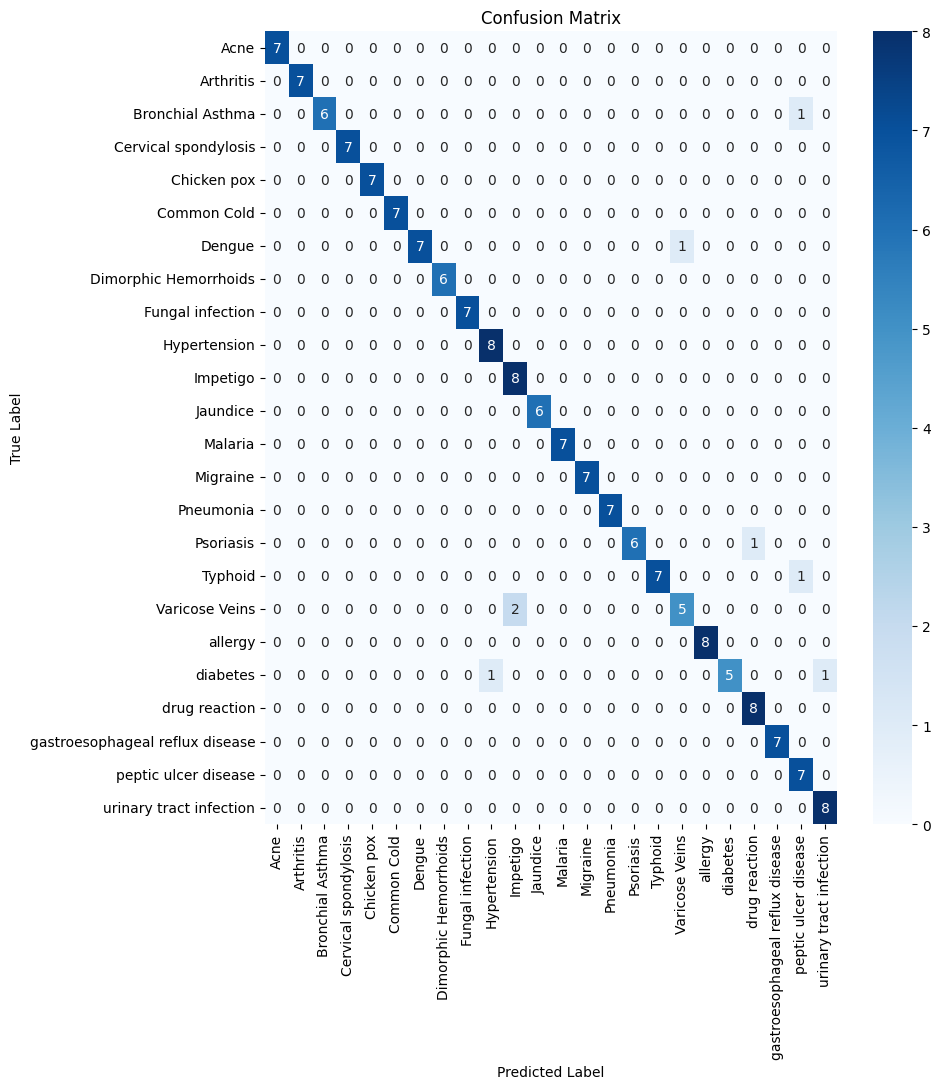

In [39]:
cm = confusion_matrix(
    y_test,
    test_pred
)

plt.figure(figsize=(10, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 30: Confusion Matrix Display

<Figure size 2000x1800 with 0 Axes>

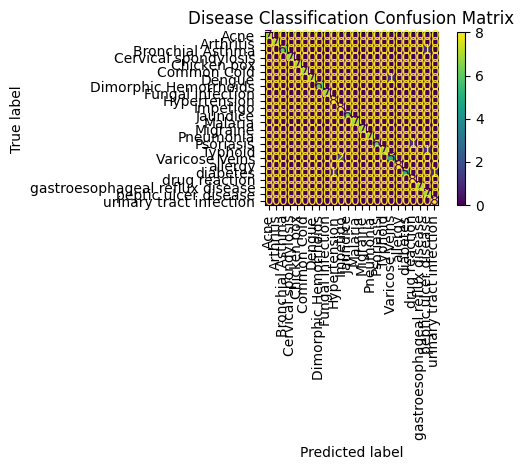

In [40]:
plt.figure(figsize=(20, 18))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=encoder.classes_,
    xticks_rotation=90
)

plt.title("Disease Classification Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 31: Predict disease from a new symptom description

In [41]:
input_text = """
I've been experiencing stiffness in my neck and my joints have swollen.
I've also been experiencing pain when I walk.
"""

print("Input symptoms:")
print(input_text)

Input symptoms:

I've been experiencing stiffness in my neck and my joints have swollen.
I've also been experiencing pain when I walk.



In [42]:
def preprocess_text(text, max_length):
    inputs = tokenizer(
        text,
        max_length=max_length,
        padding="max_length",
        truncation=True,
        return_tensors="np",
        return_attention_mask=True,
        return_token_type_ids=False,
        add_special_tokens=True
    )

    return inputs

# Clean the text exactly like the training data (BERT was trained on cleaned text)
input_text_clean = clean_single_text(input_text)
print("Cleaned input:", input_text_clean)

inputs = preprocess_text(
    input_text_clean,
    max_len
)

prediction = model.predict(
    {
        "input_ids": inputs["input_ids"],
        "attention_mask": inputs["attention_mask"]
    }
)

predicted_class = np.argmax(
    prediction,
    axis=1
)[0]

predicted_disease = labels_dict[predicted_class]
confidence = prediction[0][predicted_class] * 100

print("======================================")
print("DISEASE PREDICTION")
print("======================================")
print("Predicted Disease:", predicted_disease)
print("Prediction Confidence:", round(confidence, 2), "%")

Cleaned input: i ve experiencing stiffness neck joints swollen i ve also experiencing pain walk
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 416ms/step
DISEASE PREDICTION
Predicted Disease: Arthritis
Prediction Confidence: 83.78 %


## Step 32: Show top 5 disease predictions

In [43]:
top_5_indices = np.argsort(
    prediction[0]
)[-5:][::-1]

print("======================================")
print("TOP 5 PREDICTIONS")
print("======================================")

for index in top_5_indices:
    disease = labels_dict[index]
    probability = prediction[0][index] * 100

    print(f"{disease}: {probability:.2f}%")

TOP 5 PREDICTIONS
Arthritis: 83.78%
Migraine: 13.25%
Common Cold: 0.93%
allergy: 0.89%
Dimorphic Hemorrhoids: 0.45%


## Step 33: Save the trained model and label mapping

In [44]:
import json

# Save only the model weights instead of the whole model to bypass custom layer serialization errors
model.save_weights("symptoms_disease_classifier_final_weights.weights.h5")

with open("disease_label_mapping.json", "w") as f:
    json.dump(labels_dict, f, indent=4)

print("Model weights saved as: symptoms_disease_classifier_final_weights.weights.h5")
print("Label mapping saved as: disease_label_mapping.json")

Model weights saved as: symptoms_disease_classifier_final_weights.weights.h5
Label mapping saved as: disease_label_mapping.json


## Step 34: Download the trained files

In [45]:
from google.colab import files

files.download("symptoms_disease_classifier_final_weights.weights.h5")
files.download("disease_label_mapping.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 35: Web UI (Gradio)

This builds a simple web interface that runs **both trained models** side by side. Type a symptom description, press Submit, and see the top-5 predictions from BERT and from TF-IDF + Logistic Regression. Run all earlier cells first so both models are trained. When the last cell runs, Gradio prints a public `https://....gradio.live` link you can open and show your professor.

In [46]:
!pip install -q gradio

In [47]:
import gradio as gr

def top_k(probs, k=5):
    idx = np.argsort(probs)[-k:][::-1]
    return {str(encoder.classes_[i]): float(probs[i]) for i in idx}

def predict_ui(symptoms):
    if symptoms is None or not symptoms.strip():
        return {}, {}, "Please enter a symptom description."

    cleaned = clean_single_text(symptoms)
    if not cleaned.strip():
        return {}, {}, "No meaningful words left after cleaning. Please describe your symptoms in more detail."

    # BERT + classifier head
    enc = tokenizer(
        cleaned,
        max_length=max_len,
        padding="max_length",
        truncation=True,
        return_tensors="np",
        return_attention_mask=True,
        return_token_type_ids=False,
        add_special_tokens=True
    )
    bert_probs = model.predict(
        {"input_ids": enc["input_ids"], "attention_mask": enc["attention_mask"]},
        verbose=0
    )[0]

    # TF-IDF + Logistic Regression
    tfidf_probs = tfidf_model.predict_proba(tfidf_vectorizer.transform([cleaned]))[0]

    bert_best = encoder.classes_[int(np.argmax(bert_probs))]
    tfidf_best = encoder.classes_[int(np.argmax(tfidf_probs))]
    if bert_best == tfidf_best:
        summary = f"Both models agree: **{bert_best}**"
    else:
        summary = f"Models disagree. BERT: **{bert_best}** | TF-IDF: **{tfidf_best}**"
    summary += "\n\n*Academic project only, not medical advice.*"

    return top_k(bert_probs), top_k(tfidf_probs), summary

examples = [
    ["I have been experiencing a skin rash on my arms and legs, and my skin is peeling around my knees and elbows."],
    ["I have stiffness in my neck, swollen joints, and pain when walking."],
    ["I have a high fever, severe headache, and pain behind my eyes with joint pain."],
    ["I feel a burning sensation when I urinate and need to go very often."],
]

demo = gr.Interface(
    fn=predict_ui,
    inputs=gr.Textbox(lines=4, label="Describe your symptoms", placeholder="e.g. I have a cough, fever and chest pain..."),
    outputs=[
        gr.Label(num_top_classes=5, label="BERT (frozen) + classifier head"),
        gr.Label(num_top_classes=5, label="TF-IDF + Logistic Regression"),
        gr.Markdown(label="Summary"),
    ],
    examples=examples,
    title="Symptom2Disease: BERT vs TF-IDF",
    description="Enter a symptom description. Two NLP models predict the most likely disease.",
    flagging_mode="never",
)

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f5cd0628a630f03373.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Conclusion

Two NLP algorithms were applied to the Symptom2Disease dataset: a **frozen pretrained BERT feature extractor with a trained classifier head**, and **TF-IDF + Logistic Regression**. Both used identical preprocessing and the same stratified 70/15/15 split. See the comparison table (Accuracy, Macro-F1, Weighted-F1) above for the final results. The dataset is small and its descriptions are fairly templated, so a simple TF-IDF model can perform as well as or better than BERT here; BERT's advantage is in capturing meaning beyond exact word overlap.